# ヒール較正の可視化 ―― 既知区間で出した式を未知区間へ適用

**やること**: 既知区間(TVT_input既知)で `水平GR ≈ a*typeGR + b` の a,b を出し、**それを未知区間(eval)へそのまま適用**。
- 「真値」= 真TVTでのtypewell GR(=水平GRが本来一致すべき参照)。
- 「較正前」= 生の水平GR。「較正後」= `(水平GR − b)/a`(typewellスケールへ載せ替え)。
- 既知/未知それぞれで **較正前→較正後→真値** をプロットし、一致がどう変わるかを見る。

**注意(数学)**: 較正は線形変換なので**相関(波形の形)は変えない**(アフィン不変)。変わるのは**値の一致(RMSE)**。
本当の問い = 「**既知で出した a,b が未知区間でも通用するか(転移するか)**」。それを既知 vs 未知の一致で測る。

In [16]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
TR = Path("../rogii-wellbore-geology-prediction/train")
HARD = ["b8c49c1a","113011eb","91db7070","a2e8e7f6","1b82b665","73348914","86454a6f","e7818f7a",
        "91b301ce","efe96181","70925e23","173ed841","abf460d2","1d3fbf02","4ed93db6","ab112491",
        "4caa7289","55efee7f","708caea9","43b06c70"]

def affine(x, y):
    """y ~ a*x + b を閉形式で。"""
    ok = np.isfinite(x)&np.isfinite(y)
    if ok.sum()<10 or np.var(x[ok])<1e-6: return 1.0, 0.0
    x,y = x[ok],y[ok]
    a = float(np.cov(x,y,bias=True)[0,1]/np.var(x)); a=float(np.clip(a,0.2,3.0))
    return a, float(y.mean()-a*x.mean())

def rmse(u,v):
    e=(u-v); e=e[np.isfinite(e)]; return float(np.sqrt(np.mean(e**2))) if len(e) else np.nan
def corr(u,v):
    ok=np.isfinite(u)&np.isfinite(v)
    if ok.sum()<5 or np.std(u[ok])<1e-6 or np.std(v[ok])<1e-6: return np.nan
    return float(np.corrcoef(u[ok],v[ok])[0,1])

def load(wid):
    hw=pd.read_csv(TR/f"{wid}__horizontal_well.csv")
    tw=pd.read_csv(TR/f"{wid}__typewell.csv").sort_values("TVT")
    if "TVT" not in hw.columns or hw.TVT.isna().all(): return None
    kn=hw[hw.TVT_input.notna()]; ev=hw[hw.TVT_input.isna()]
    if len(kn)<10 or len(ev)<5: return None
    tw_tvt=tw.TVT.to_numpy(float); tw_gr=tw.GR.to_numpy(float)
    grh = hw.GR.astype(float).interpolate(limit_direction="both").to_numpy(float)
    kpos=hw.index.get_indexer(kn.index); epos=hw.index.get_indexer(ev.index)
    d=dict(
        kmd=kn.MD.to_numpy(float), kgr=grh[kpos], ktrue=kn.TVT_input.to_numpy(float),
        emd=ev.MD.to_numpy(float), egr=grh[epos], etrue=ev.TVT.to_numpy(float),
        tw_tvt=tw_tvt, tw_gr=tw_gr)
    d["k_ref"]=np.interp(d["ktrue"], tw_tvt, tw_gr)    # 真値: 真TVTでのtypewell GR(既知)
    d["e_ref"]=np.interp(d["etrue"], tw_tvt, tw_gr)    # 真値(未知, train真値)
    return d
print("helpers ready | hard:", len(HARD))

helpers ready | hard: 20


In [17]:
# ===== 1坑井: 既知で a,b → 未知へ適用。指標を計算 =====
def analyze(wid):
    d=load(wid)
    if d is None: return None
    # 既知区間で 水平GR ~ a*typeGR_ref + b
    a,b = affine(d["k_ref"], d["kgr"])
    # 較正後の水平GR(typewellスケールへ): (GRh - b)/a
    kcal=(d["kgr"]-b)/a; ecal=(d["egr"]-b)/a
    m=dict(wid=wid,a=a,b=b,
        # 形の相関(較正不変。既知 vs 未知で変わる)
        corr_known=corr(d["kgr"], d["k_ref"]), corr_eval=corr(d["egr"], d["e_ref"]),
        # 値の一致RMSE(較正前→後)。既知と未知で。
        rmse_k_before=rmse(d["kgr"], d["k_ref"]), rmse_k_after=rmse(kcal, d["k_ref"]),
        rmse_e_before=rmse(d["egr"], d["e_ref"]), rmse_e_after=rmse(ecal, d["e_ref"]))
    return d,m,kcal,ecal

def plot_well(wid):
    r=analyze(wid)
    if r is None: print("skip",wid); return
    d,m,kcal,ecal=r
    fig,ax=plt.subplots(1,2,figsize=(15,4.2))
    # 既知区間
    ax[0].plot(d["kmd"], d["k_ref"], color="k", lw=1.4, label="真値=typeGR@trueTVT")
    ax[0].plot(d["kmd"], d["kgr"], color="tab:red", alpha=.6, lw=.9, label="較正前(生 水平GR)")
    ax[0].plot(d["kmd"], kcal, color="tab:blue", alpha=.8, lw=.9, label="較正後 (GRh-b)/a")
    ax[0].set_title(f"{wid} 既知区間  a={m['a']:.2f} b={m['b']:+.0f}\n"
                    f"corr={m['corr_known']:.2f}  RMSE {m['rmse_k_before']:.1f}->{m['rmse_k_after']:.1f}")
    ax[0].set_xlabel("MD"); ax[0].legend(fontsize=8)
    # 未知区間(既知の a,b を流用)
    ax[1].plot(d["emd"], d["e_ref"], color="k", lw=1.4, label="真値=typeGR@trueTVT")
    ax[1].plot(d["emd"], d["egr"], color="tab:red", alpha=.6, lw=.9, label="較正前")
    ax[1].plot(d["emd"], ecal, color="tab:blue", alpha=.8, lw=.9, label="較正後(既知a,b流用)")
    ax[1].set_title(f"{wid} 未知区間(eval)  corr={m['corr_eval']:.2f}  "
                    f"RMSE {m['rmse_e_before']:.1f}->{m['rmse_e_after']:.1f}")
    ax[1].set_xlabel("MD"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    return m

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 26082 (\N{CJK UNIFIED IDEOGRAPH-65E2}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 38291 (\N{CJK UNIFIED IDEOGRAPH-9593}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\A

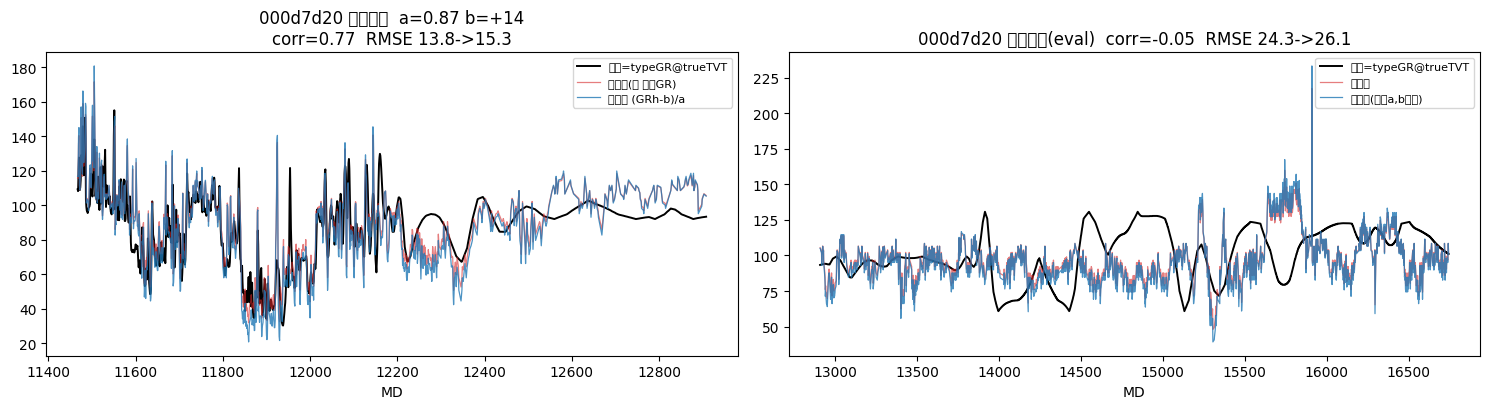

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 26082 (\N{CJK UNIFIED IDEOGRAPH-65E2}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 38291 (\N{CJK UNIFIED IDEOGRAPH-9593}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\A

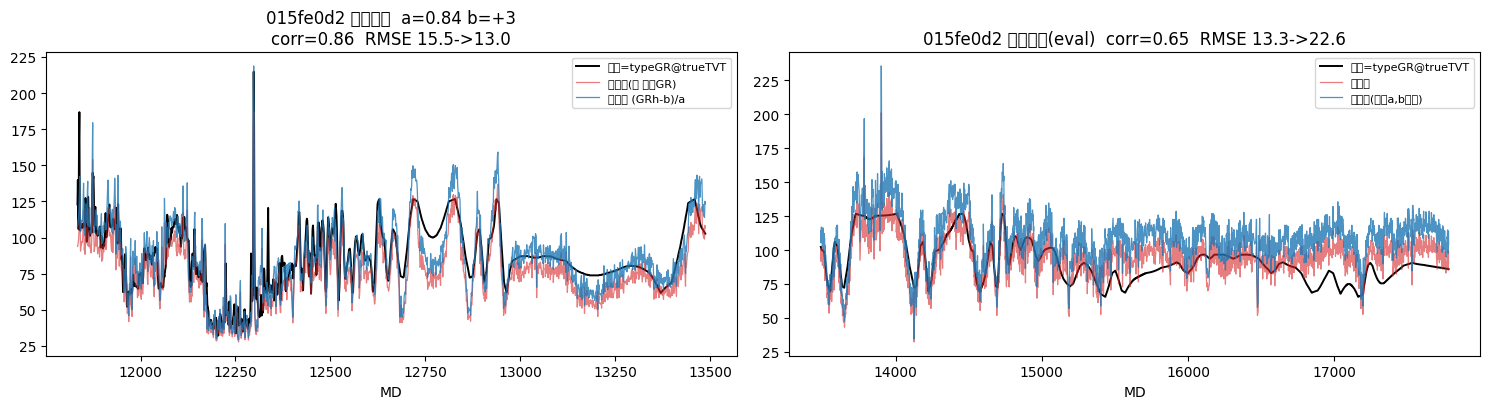

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 26082 (\N{CJK UNIFIED IDEOGRAPH-65E2}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 38291 (\N{CJK UNIFIED IDEOGRAPH-9593}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\A

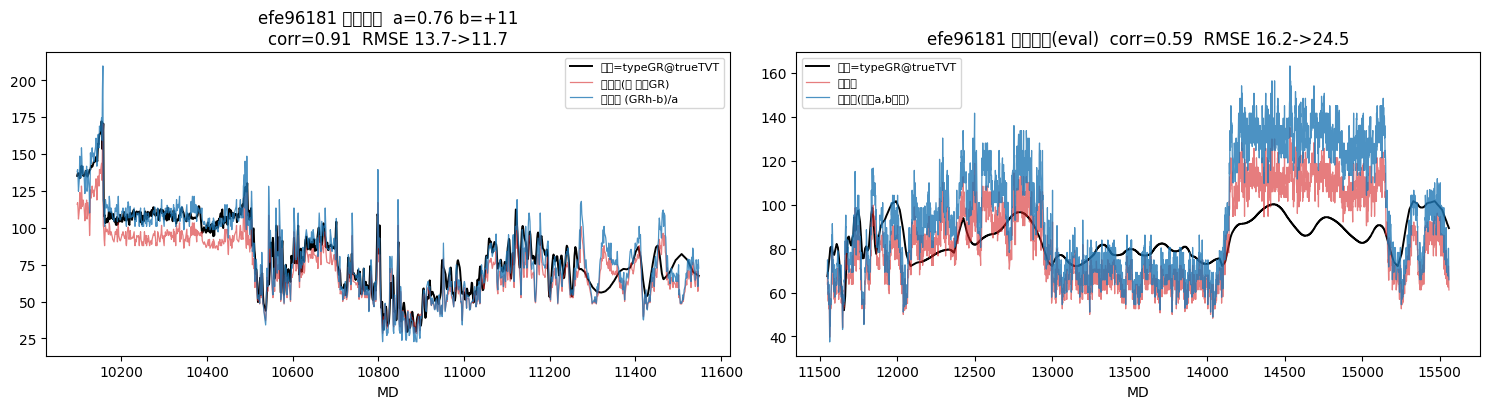

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 26082 (\N{CJK UNIFIED IDEOGRAPH-65E2}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 21306 (\N{CJK UNIFIED IDEOGRAPH-533A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 38291 (\N{CJK UNIFIED IDEOGRAPH-9593}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\336637369.py:36: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\A

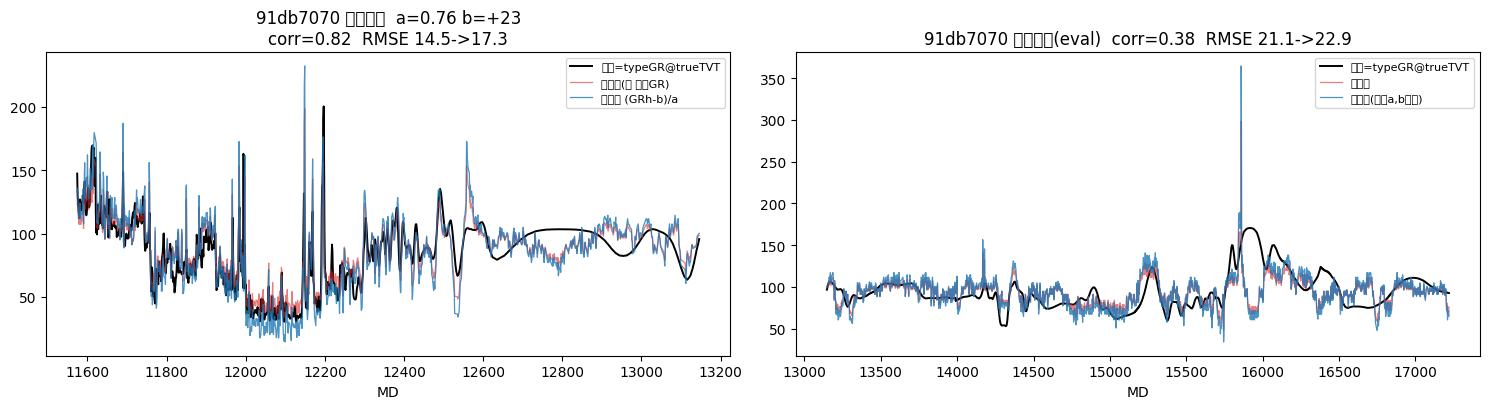

In [18]:
# ===== 例: 易坑井2 + 硬い核2 を可視化 =====
for wid in ["000d7d20","015fe0d2","efe96181","91db7070"]:
    plot_well(wid)

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 20516 (\N{CJK UNIFIED IDEOGRAPH-5024}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

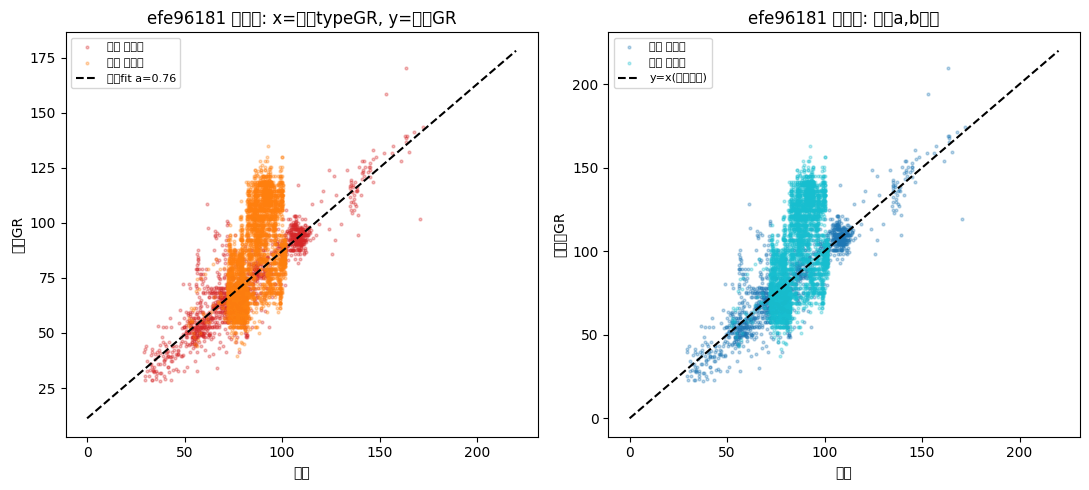

C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 20516 (\N{CJK UNIFIED IDEOGRAPH-5024}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 27700 (\N{CJK UNIFIED IDEOGRAPH-6C34}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 24179 (\N{CJK UNIFIED IDEOGRAPH-5E73}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1024571929.py:15: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

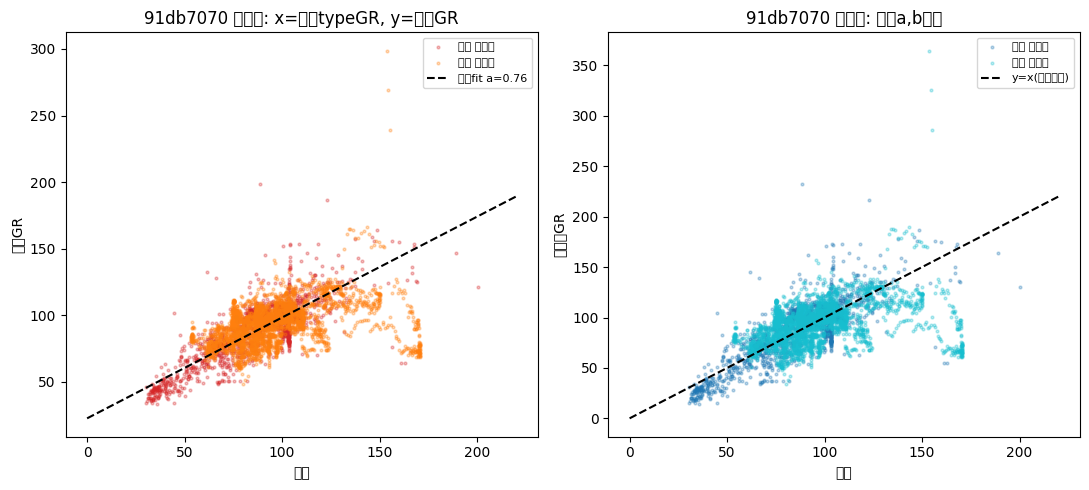

In [19]:
# ===== 散布: 較正前後の水平GR vs 真値(既知/未知) 1坑井 =====
def scatter_well(wid):
    r=analyze(wid)
    if r is None: return
    d,m,kcal,ecal=r
    fig,ax=plt.subplots(1,2,figsize=(11,5))
    ax[0].scatter(d["k_ref"], d["kgr"], s=4, alpha=.3, color="tab:red", label="既知 較正前")
    ax[0].scatter(d["e_ref"], d["egr"], s=4, alpha=.3, color="tab:orange", label="未知 較正前")
    lo,hi=0,220; ax[0].plot([lo,hi],[m['a']*lo+m['b'],m['a']*hi+m['b']],"k--",label=f"既知fit a={m['a']:.2f}")
    ax[0].set_title(f"{wid} 較正前: x=真値typeGR, y=水平GR"); ax[0].set_xlabel("真値"); ax[0].set_ylabel("水平GR"); ax[0].legend(fontsize=8)
    ax[1].scatter(d["k_ref"], kcal, s=4, alpha=.3, color="tab:blue", label="既知 較正後")
    ax[1].scatter(d["e_ref"], ecal, s=4, alpha=.3, color="tab:cyan", label="未知 較正後")
    ax[1].plot([lo,hi],[lo,hi],"k--",label="y=x(完全一致)")
    ax[1].set_title(f"{wid} 較正後: 既知a,b流用"); ax[1].set_xlabel("真値"); ax[1].set_ylabel("較正後GR"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
scatter_well("efe96181"); scatter_well("91db7070")

In [20]:
# ===== 集計データ作成: 多数坑井 =====
import glob, os
wells=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))
rows=[]
for wid in wells[:773]:
    r=analyze(wid)
    if r is not None: rows.append(r[1])
df=pd.DataFrame(rows); df["is_hard"]=df.wid.isin(HARD)
df["d_corr"]   = df.corr_eval - df.corr_known       # 形の対応: 既知→未知の変化(±)
df["d_rmse_e"] = df.rmse_e_after - df.rmse_e_before  # 較正の未知への効果(負=改善, 正=悪化)
print("集計坑井:", len(df))

集計坑井: 773


=== 較正(既知a,b)を未知へ適用した効果 ===
  改善(RMSE -0.5超) : 11坑井 (1%)
  悪化(RMSE +0.5超) : 714坑井 (92%)
  ほぼ不変           : 48坑井
  未知マッチRMSE中央: 較正前 10.55 → 較正後 13.41
  d_rmse 中央=+2.38  平均=+3.47
  ※ 注: 相関(波形の形)はアフィン較正で不変。変わるのは値の一致(RMSE)。

=== 波形相関 既知→未知(地質の転移) ===
  corr 既知中央=0.817  未知中央=0.668
  未知で相関UP: 76坑井 / DOWN: 541坑井
  硬い核: corr既知=0.786 未知=0.590 d_rmse中央=+3.61


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3097217410.py:39: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3097217410.py:39: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3097217410.py:39: UserWarning: Glyph 12398 (\N{HIRAGANA LETTER NO}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3097217410.py:39: UserWarning: Glyph 26410 (\N{CJK UNIFIED IDEOGRAPH-672A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3097217410.py:39: UserWarning: Glyph 30693 (\N{CJK UNIFIED IDEOGRAPH-77E5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppD

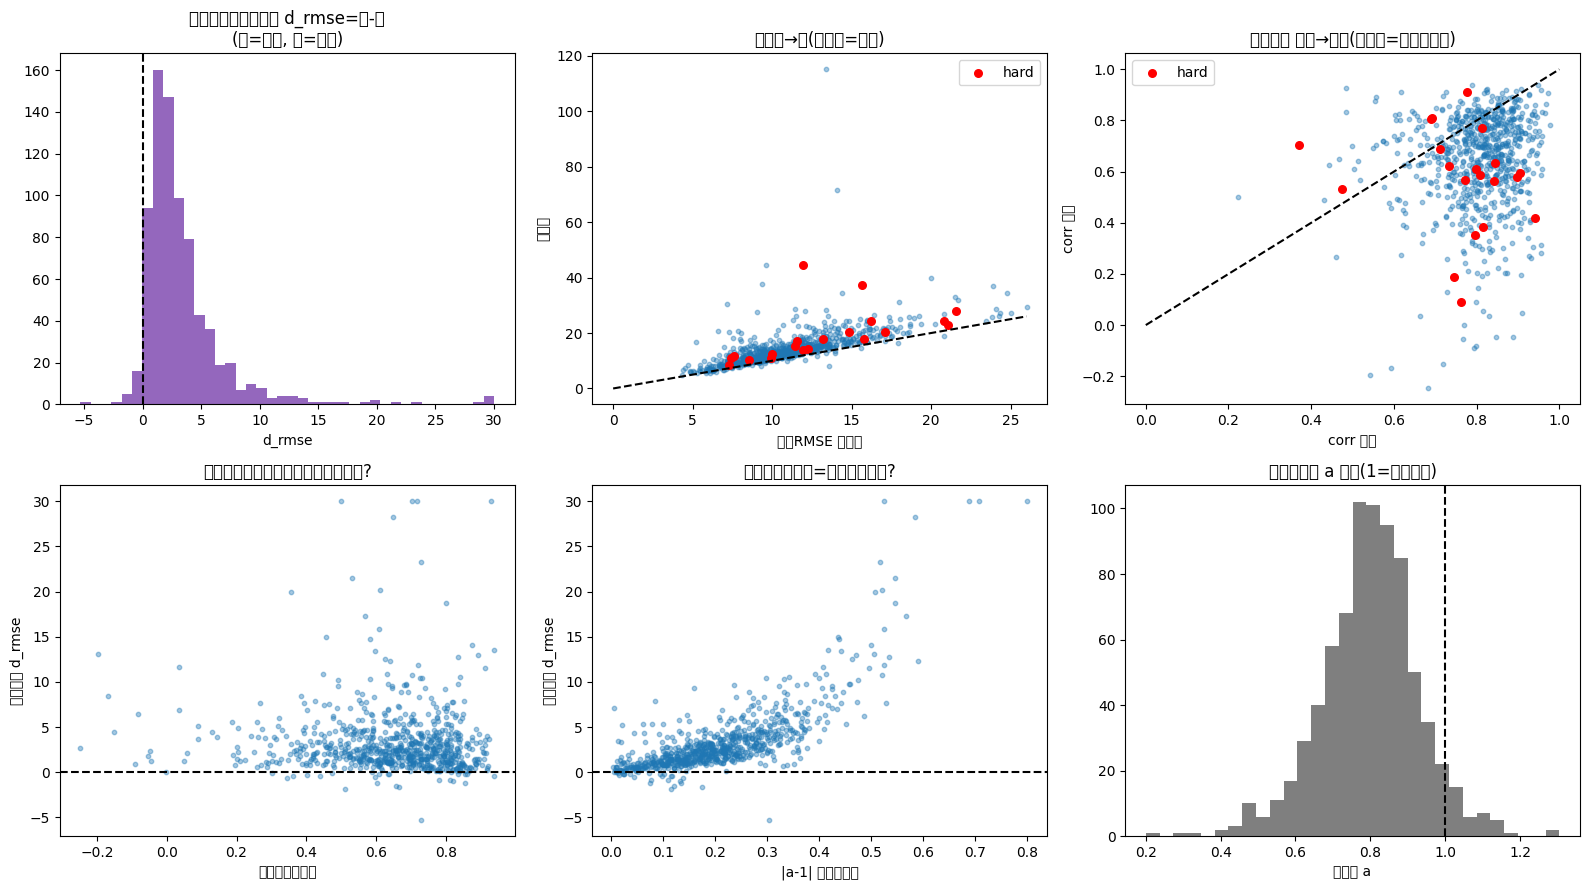

In [21]:
# ===== 総合評価1: 較正は未知へ転移するか(上がる/下がる両方を定量化) =====
imp = (df.d_rmse_e < -0.5).sum(); hurt = (df.d_rmse_e > 0.5).sum(); neu = len(df)-imp-hurt
poolb = float(np.sqrt(np.nanmean(df.rmse_e_before**2))); poola=float(np.sqrt(np.nanmean(df.rmse_e_after**2)))
print("=== 較正(既知a,b)を未知へ適用した効果 ===")
print(f"  改善(RMSE -0.5超) : {imp}坑井 ({100*imp/len(df):.0f}%)")
print(f"  悪化(RMSE +0.5超) : {hurt}坑井 ({100*hurt/len(df):.0f}%)")
print(f"  ほぼ不変           : {neu}坑井")
print(f"  未知マッチRMSE中央: 較正前 {df.rmse_e_before.median():.2f} → 較正後 {df.rmse_e_after.median():.2f}")
print(f"  d_rmse 中央={df.d_rmse_e.median():+.2f}  平均={df.d_rmse_e.mean():+.2f}")
print(f"  ※ 注: 相関(波形の形)はアフィン較正で不変。変わるのは値の一致(RMSE)。")
print(f"\n=== 波形相関 既知→未知(地質の転移) ===")
print(f"  corr 既知中央={df.corr_known.median():.3f}  未知中央={df.corr_eval.median():.3f}")
print(f"  未知で相関UP: {(df.d_corr>0.05).sum()}坑井 / DOWN: {(df.d_corr<-0.05).sum()}坑井")
print(f"  硬い核: corr既知={df[df.is_hard].corr_known.median():.3f} 未知={df[df.is_hard].corr_eval.median():.3f} d_rmse中央={df[df.is_hard].d_rmse_e.median():+.2f}")

fig,ax=plt.subplots(2,3,figsize=(16,9))
# (1) 較正効果のヒスト(上下両方)
ax[0,0].hist(df.d_rmse_e.clip(-30,30), bins=40, color="tab:purple"); ax[0,0].axvline(0,color="k",ls="--")
ax[0,0].set_title("較正の未知への効果 d_rmse=後-前\n(左=改善, 右=悪化)"); ax[0,0].set_xlabel("d_rmse")
# (2) 較正前→後 RMSE 散布(対角下=改善)
ax[0,1].scatter(df.rmse_e_before, df.rmse_e_after, s=10, alpha=.4)
ax[0,1].scatter(df[df.is_hard].rmse_e_before, df[df.is_hard].rmse_e_after, s=30, color="red", label="hard")
mx=float(np.nanmax(df.rmse_e_before)); ax[0,1].plot([0,mx],[0,mx],"k--")
ax[0,1].set_xlabel("未知RMSE 較正前"); ax[0,1].set_ylabel("較正後"); ax[0,1].set_title("較正前→後(対角下=改善)"); ax[0,1].legend()
# (3) 波形相関 既知 vs 未知
ax[0,2].scatter(df.corr_known, df.corr_eval, s=10, alpha=.4)
ax[0,2].scatter(df[df.is_hard].corr_known, df[df.is_hard].corr_eval, s=30, color="red", label="hard")
ax[0,2].plot([0,1],[0,1],"k--"); ax[0,2].set_xlabel("corr 既知"); ax[0,2].set_ylabel("corr 未知")
ax[0,2].set_title("波形相関 既知→未知(対角下=未知で劣化)"); ax[0,2].legend()
# (4) 「いつ較正が効くか」: d_rmse vs 未知corr
ax[1,0].scatter(df.corr_eval, df.d_rmse_e.clip(-30,30), s=10, alpha=.4); ax[1,0].axhline(0,color="k",ls="--")
ax[1,0].set_xlabel("未知の波形相関"); ax[1,0].set_ylabel("較正効果 d_rmse"); ax[1,0].set_title("未知で形が合う坑井ほど較正は効く?")
# (5) d_rmse vs |a-1|(目盛りズレが大きいほど較正の余地)
ax[1,1].scatter((df.a-1).abs(), df.d_rmse_e.clip(-30,30), s=10, alpha=.4); ax[1,1].axhline(0,color="k",ls="--")
ax[1,1].set_xlabel("|a-1| 目盛りズレ"); ax[1,1].set_ylabel("較正効果 d_rmse"); ax[1,1].set_title("目盛りズレが大=較正の効果大?")
# (6) ゲインa分布
ax[1,2].hist(df.a.dropna(), bins=30, color="tab:gray"); ax[1,2].axvline(1.0,color="k",ls="--")
ax[1,2].set_xlabel("ゲイン a"); ax[1,2].set_title("較正ゲイン a 分布(1=ズレ無し)")
plt.tight_layout(); plt.show()

In [22]:
# ===== 総合評価2: 較正が大きく効いた/裏目に出た坑井 一覧 =====
show=df.copy()
show["a"]=show.a.round(2); show["b"]=show.b.round(0)
cols=["wid","is_hard","a","b","corr_known","corr_eval","rmse_e_before","rmse_e_after","d_rmse_e"]
print("=== 較正で最も悪化した10坑井(転移失敗=未知で別の関係) ===")
print(show.sort_values("d_rmse_e",ascending=False)[cols].head(10).round(2).to_string(index=False))
print("\n=== 較正で最も改善した10坑井(目盛りズレが大きく転移成功) ===")
print(show.sort_values("d_rmse_e")[cols].head(10).round(2).to_string(index=False))

=== 較正で最も悪化した10坑井(転移失敗=未知で別の関係) ===
     wid  is_hard    a    b  corr_known  corr_eval  rmse_e_before  rmse_e_after  d_rmse_e
19137a89    False 0.29 72.0        0.48       0.93          13.37        115.12    101.74
d60430e6    False 0.20 67.0        0.22       0.50          14.08         71.67     57.59
d1457cc5    False 0.47 26.0        0.57       0.72           9.61         44.47     34.87
173ed841     True 0.31 65.0        0.37       0.70          11.93         44.52     32.59
c03b9305    False 0.42 35.0        0.47       0.65           9.37         37.63     28.26
29b24409    False 0.48 32.0        0.61       0.73           7.17         30.39     23.22
70925e23     True 0.45 53.0        0.47       0.53          15.67         37.15     21.48
5305524b    False 0.48 39.0        0.50       0.61          14.37         34.55     20.18
d0a43760    False 0.49 35.0        0.67       0.36          19.97         39.97     20.00
8f201368    False 0.45 39.0        0.62       0.80           9.0

集計坑井: 400

=== 絶対一致(公平な向き typewell->horizontal) ===
  eval RMSE中央: 較正前 10.61 -> 較正後 10.52  (改善 28% / 悪化 26%)
=== 位置特定(シフトスキャン, 0=真に一致) ===
  2ft以内で特定: 較正なし 88%  較正あり 84%
  位置特定 改善 3% / 悪化 7%
  ★結論: このデータは素のGRで既に高率特定。較正は絶対一致ほぼ不変・位置特定も改善せず=目盛りずれは主要因でない。


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3802567142.py:42: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3802567142.py:42: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3802567142.py:42: UserWarning: Glyph 21177 (\N{CJK UNIFIED IDEOGRAPH-52B9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3802567142.py:42: UserWarning: Glyph 26524 (\N{CJK UNIFIED IDEOGRAPH-679C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3802567142.py:42: UserWarning: Glyph 20844 (\N{CJK UNIFIED IDEOGRAPH-516C}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

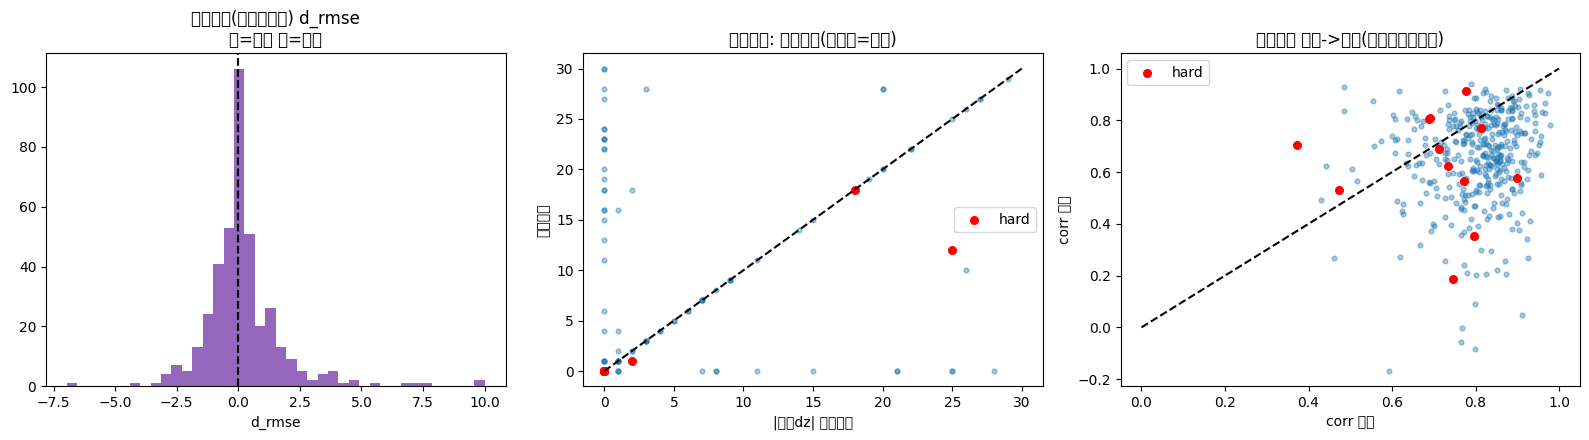

In [23]:
# ===== 【訂正版】正しい指標で総合評価: 公平な向きRMSE + シフトスキャン位置特定 =====
# 前セルの d_rmse は (GRh-b)/a の向きで a<1 だと増幅して水増し → ここで修正。
# 較正の本来の目的は「位置特定(どの深さか)」なのでシフトスキャンで測る。
import glob, os
OFF=np.arange(-30,30.01,1.0)
def analyze2(wid):
    d=load(wid)
    if d is None: return None
    a,b=affine(d["k_ref"], d["kgr"])
    # 公平な向き typewell->horizontal: rmse(GRh, a*ref+b)
    e_before=rmse(d["egr"], d["e_ref"]); e_after=rmse(d["egr"], a*d["e_ref"]+b)
    # 位置特定: eval全体を dz ずらして misfit最小がどこか(0=真)
    def loc(cal):
        ms=[rmse(d["egr"], (a*np.interp(d["etrue"]+dz,d["tw_tvt"],d["tw_gr"])+b) if cal
                            else np.interp(d["etrue"]+dz,d["tw_tvt"],d["tw_gr"])) for dz in OFF]
        return abs(OFF[int(np.argmin(ms))])
    return dict(wid=wid,a=a,b=b,is_hard=wid in HARD,
                corr_known=corr(d["kgr"],d["k_ref"]), corr_eval=corr(d["egr"],d["e_ref"]),
                e_before=e_before, e_after=e_after, d_rmse_fair=e_after-e_before,
                loc_raw=loc(False), loc_calib=loc(True))

wells=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))
R=[analyze2(w) for w in wells[:400]]; R=[r for r in R if r]
g=pd.DataFrame(R)
print("集計坑井:",len(g))
print("\n=== 絶対一致(公平な向き typewell->horizontal) ===")
print(f"  eval RMSE中央: 較正前 {g.e_before.median():.2f} -> 較正後 {g.e_after.median():.2f}  (改善 {(g.d_rmse_fair<-0.5).mean()*100:.0f}% / 悪化 {(g.d_rmse_fair>0.5).mean()*100:.0f}%)")
print("=== 位置特定(シフトスキャン, 0=真に一致) ===")
print(f"  2ft以内で特定: 較正なし {(g.loc_raw<=2).mean()*100:.0f}%  較正あり {(g.loc_calib<=2).mean()*100:.0f}%")
print(f"  位置特定 改善 {(g.loc_calib<g.loc_raw-1).mean()*100:.0f}% / 悪化 {(g.loc_calib>g.loc_raw+1).mean()*100:.0f}%")
print(f"  ★結論: このデータは素のGRで既に高率特定。較正は絶対一致ほぼ不変・位置特定も改善せず=目盛りずれは主要因でない。")

fig,ax=plt.subplots(1,3,figsize=(16,4.5))
ax[0].hist(g.d_rmse_fair.clip(-10,10),bins=40,color="tab:purple"); ax[0].axvline(0,color="k",ls="--")
ax[0].set_title("較正効果(公平な向き) d_rmse\n左=改善 右=悪化"); ax[0].set_xlabel("d_rmse")
ax[1].scatter(g.loc_raw, g.loc_calib, s=12, alpha=.4); ax[1].plot([0,30],[0,30],"k--")
ax[1].scatter(g[g.is_hard].loc_raw,g[g.is_hard].loc_calib,s=30,color="red",label="hard")
ax[1].set_xlabel("|最良dz| 較正なし"); ax[1].set_ylabel("較正あり"); ax[1].set_title("位置特定: 較正前後(対角下=改善)"); ax[1].legend()
ax[2].scatter(g.corr_known,g.corr_eval,s=12,alpha=.4); ax[2].plot([0,1],[0,1],"k--")
ax[2].scatter(g[g.is_hard].corr_known,g[g.is_hard].corr_eval,s=30,color="red",label="hard")
ax[2].set_xlabel("corr 既知"); ax[2].set_ylabel("corr 未知"); ax[2].set_title("波形相関 既知->未知(これは上下する)"); ax[2].legend()
plt.tight_layout(); plt.show()

集計坑井: 300

     窓     eval一致RMSE中央     位置特定2ft%     a中央   a std
   raw            10.60          86%   (較正なし)
   L50            15.24          56%    0.58    1.00
  L100            13.96          61%    0.67    0.82
  L200            12.43          70%    0.73    0.65
  full            10.58          83%    0.81    0.14


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3032830285.py:46: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3032830285.py:46: UserWarning: Glyph 32622 (\N{CJK UNIFIED IDEOGRAPH-7F6E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3032830285.py:46: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3032830285.py:46: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3032830285.py:46: UserWarning: Glyph 20197 (\N{CJK UNIFIED IDEOGRAPH-4EE5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

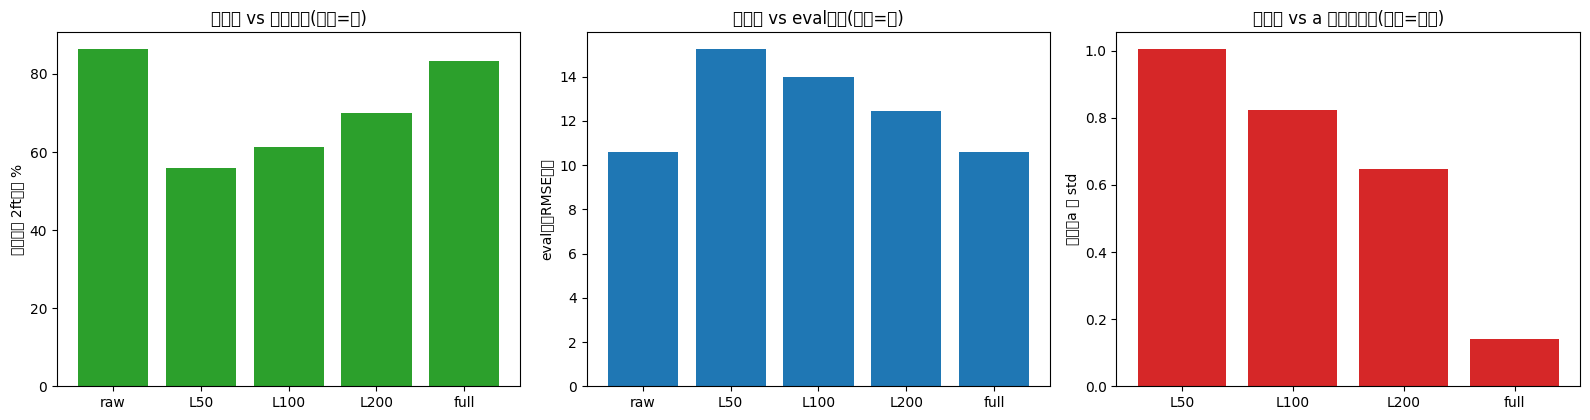


★読み: 窓が短い(直前50)ほど 縦の振れ不足で a が暴れ(std大)→ 位置特定もRMSEも悪化。
  全既知ゾーン(ビルド/ランディング含む)が最も安定。ただし生(較正なし)が依然最良=目盛りずれは主要因でない。


In [24]:
# ===== 較正窓の長さ比較: 直前N区間 vs 全既知ゾーン(位置特定・eval一致・a安定性) =====
# CAL_LAST=N で「未知の直前N区間だけ」で a,b をフィット。None=既知ゾーン全体。N をスイープして傾向を見る。
import glob, os
OFFs=np.arange(-30,30.01,1.0)
def fit_window(d, last_n):
    """既知ゾーンの (直前last_n行 or 全体) で 水平GR~a*typeGR+b を返す。"""
    kr=d["k_ref"]; kg=d["kgr"]
    if last_n is not None and len(kr)>last_n: kr,kg=kr[-last_n:],kg[-last_n:]
    return affine(kr, kg)
def eval_with(d, a, b):
    em=rmse(d["egr"], a*d["e_ref"]+b)                               # 公平な向きの絶対一致
    ms=[rmse(d["egr"], a*np.interp(d["etrue"]+dz,d["tw_tvt"],d["tw_gr"])+b) for dz in OFFs]
    return em, abs(OFFs[int(np.argmin(ms))])                        # (RMSE, 最良dz=位置ズレ)

wells=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))[:300]
WINDOWS=[50,100,200,None]      # None=全既知。ここを編集してスイープ変更可
rows=[]
for wid in wells:
    d=load(wid)
    if d is None or len(d["kgr"])<60 or len(d["egr"])<20: continue
    rec={"wid":wid,"is_hard":wid in HARD}
    # 生(較正なし=a1,b0)
    em,lc=eval_with(d,1.0,0.0); rec["raw_rmse"]=em; rec["raw_loc"]=lc
    for n in WINDOWS:
        a,b=fit_window(d,n); em,lc=eval_with(d,a,b)
        tag="full" if n is None else f"L{n}"
        rec[f"{tag}_a"]=a; rec[f"{tag}_rmse"]=em; rec[f"{tag}_loc"]=lc
    rows.append(rec)
W=pd.DataFrame(rows); print("集計坑井:",len(W))

names=["raw"]+["full" if n is None else f"L{n}" for n in WINDOWS]
print(f"\n{'窓':>6s} {'eval一致RMSE中央':>16s} {'位置特定2ft%':>12s} {'a中央':>7s} {'a std':>7s}")
for nm in names:
    rm=W[f"{nm}_rmse"].median(); loc2=(W[f"{nm}_loc"]<=2).mean()*100
    if nm=="raw": print(f"{nm:>6s} {rm:16.2f} {loc2:11.0f}%   (較正なし)")
    else: print(f"{nm:>6s} {rm:16.2f} {loc2:11.0f}% {W[nm+'_a'].median():7.2f} {W[nm+'_a'].std():7.2f}")

fig,ax=plt.subplots(1,3,figsize=(16,4.3))
xs=list(range(len(names)))
ax[0].bar(xs,[(W[f"{nm}_loc"]<=2).mean()*100 for nm in names],color="tab:green"); ax[0].set_xticks(xs); ax[0].set_xticklabels(names)
ax[0].set_ylabel("位置特定 2ft以内 %"); ax[0].set_title("較正窓 vs 位置特定(高い=良)")
ax[1].bar(xs,[W[f"{nm}_rmse"].median() for nm in names],color="tab:blue"); ax[1].set_xticks(xs); ax[1].set_xticklabels(names)
ax[1].set_ylabel("eval一致RMSE中央"); ax[1].set_title("較正窓 vs eval一致(低い=良)")
ax[2].bar(xs[1:],[W[nm+'_a'].std() for nm in names[1:]],color="tab:red"); ax[2].set_xticks(xs[1:]); ax[2].set_xticklabels(names[1:])
ax[2].set_ylabel("ゲインa の std"); ax[2].set_title("較正窓 vs a の不安定さ(低い=安定)")
plt.tight_layout(); plt.show()
print("\n★読み: 窓が短い(直前50)ほど 縦の振れ不足で a が暴れ(std大)→ 位置特定もRMSEも悪化。")
print("  全既知ゾーン(ビルド/ランディング含む)が最も安定。ただし生(較正なし)が依然最良=目盛りずれは主要因でない。")

集計坑井: 300

  window | raw loc2ft  raw rmse | cal loc2ft  cal rmse
     raw |        86%     10.60 |        83%     10.58
     MA5 |        85%     10.20 |        79%     10.63
    MA11 |        77%     12.02 |        69%     12.23
    MA21 |        35%     12.16 |        30%     12.66

=== 相補性(アンサンブル価値) ===
  MA1: 生のみ勝ち 21 / 較正のみ勝ち 12 / oracle選択 loc2ft=90%  (単独 生86% 較正83%)
  MA5: 生のみ勝ち 32 / 較正のみ勝ち 10 / oracle選択 loc2ft=88%  (単独 生85% 較正79%)
  MA11: 生のみ勝ち 42 / 較正のみ勝ち 16 / oracle選択 loc2ft=80%  (単独 生77% 較正69%)
  MA21: 生のみ勝ち 50 / 較正のみ勝ち 29 / oracle選択 loc2ft=39%  (単独 生35% 較正30%)


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\158554100.py:57: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\158554100.py:57: UserWarning: Glyph 36611 (\N{CJK UNIFIED IDEOGRAPH-8F03}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\158554100.py:57: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\158554100.py:57: UserWarning: Glyph 36984 (\N{CJK UNIFIED IDEOGRAPH-9078}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\158554100.py:57: UserWarning: Glyph 25246 (\N{CJK UNIFIED IDEOGRAPH-629E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\A

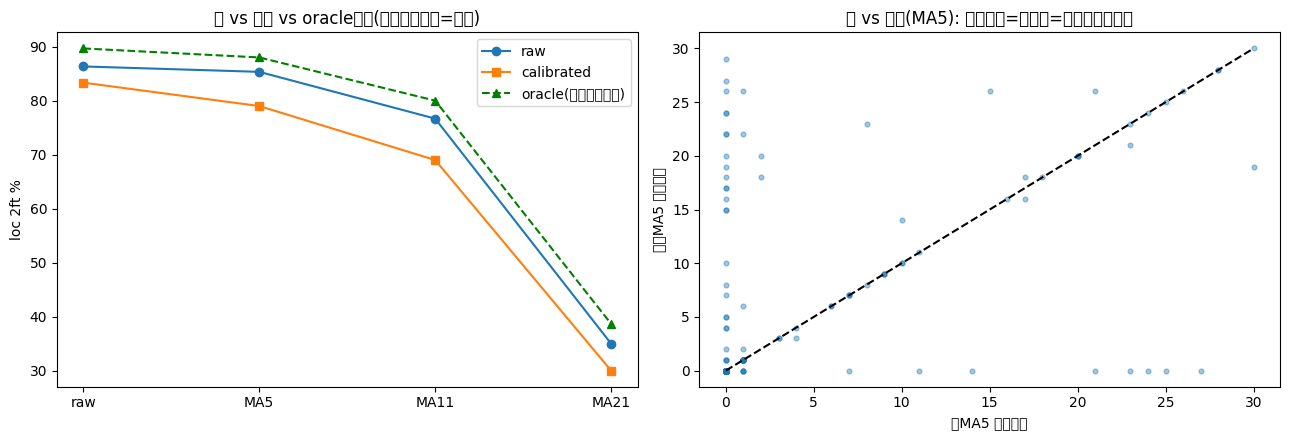


★読み: oracle(緑)が単独を上回れば 生と較正は相補=アンサンブル価値あり。較正は単独で負けても束ねる価値がある。


In [25]:
# ===== 較正 × 移動平均 マトリクス比較(+相補性=アンサンブル価値) =====
# 表現 = {生, 較正} × 平滑 = {なし, MA5, MA11, MA21}。位置特定・eval一致を測り、
# 「較正と生が別の坑井で勝つ(=相補)」かを定量化(アンサンブル価値の検証)。
import glob, os
OFFm=np.arange(-30,30.01,1.0); WINS=[1,5,11,21]
def mavg(x,w):
    if w<=1: return x
    k=np.ones(w)/w; return np.convolve(np.nan_to_num(x,nan=np.nanmean(x)),k,mode="same")

wells=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))[:300]
rows=[]
for wid in wells:
    hw=pd.read_csv(TR/f"{wid}__horizontal_well.csv"); tw=pd.read_csv(TR/f"{wid}__typewell.csv").sort_values("TVT")
    if "TVT" not in hw or hw.TVT.isna().all(): continue
    kn=hw[hw.TVT_input.notna()]; ev=hw[hw.TVT_input.isna()]
    if len(kn)<30 or len(ev)<20: continue
    grh=hw.GR.astype(float).interpolate(limit_direction="both").to_numpy(float)
    kpos=hw.index.get_indexer(kn.index); epos=hw.index.get_indexer(ev.index)
    twt=tw.TVT.to_numpy(float); twg=tw.GR.to_numpy(float)
    kgr=grh[kpos]; kref=np.interp(kn.TVT_input.to_numpy(float),twt,twg)
    a,b=affine(kref,kgr)                                  # full-known 較正
    etrue=ev.TVT.to_numpy(float)
    rec={"wid":wid,"is_hard":wid in HARD,"a":a}
    for w in WINS:
        egr=mavg(grh,w)[epos]; twg_s=mavg(twg,w) if w>1 else twg
        for cal in (False,True):
            ref=lambda dz: (a*np.interp(etrue+dz,twt,twg_s)+b) if cal else np.interp(etrue+dz,twt,twg_s)
            ms=[rmse(egr,ref(dz)) for dz in OFFm]
            key=("cal" if cal else "raw")+str(w)
            rec[f"loc_{key}"]=abs(OFFm[int(np.argmin(ms))]); rec[f"rmse_{key}"]=rmse(egr,ref(0.0))
    rows.append(rec)
G=pd.DataFrame(rows); print("集計坑井:",len(G))

print(f"\n{'window':>8s} | {'raw loc2ft':>10s} {'raw rmse':>9s} | {'cal loc2ft':>10s} {'cal rmse':>9s}")
for w in WINS:
    tag="raw" if w==1 else f"MA{w}"
    print(f"{tag:>8s} | {(G[f'loc_raw{w}']<=2).mean()*100:9.0f}% {G[f'rmse_raw{w}'].median():9.2f} | "
          f"{(G[f'loc_cal{w}']<=2).mean()*100:9.0f}% {G[f'rmse_cal{w}'].median():9.2f}")

# 相補性: 生(MA5) vs 較正(MA5) で坑井ごとの勝敗 → アンサンブル価値
print("\n=== 相補性(アンサンブル価値) ===")
for w in WINS:
    rl=G[f"loc_raw{w}"]; cl=G[f"loc_cal{w}"]
    rwin=(rl<cl-1).sum(); cwin=(cl<rl-1).sum()
    # 各坑井で良い方を採れた場合(oracle選択)の位置特定
    best=(np.minimum(rl,cl)<=2).mean()*100
    print(f"  MA{w}: 生のみ勝ち {rwin} / 較正のみ勝ち {cwin} / oracle選択 loc2ft={best:.0f}%  (単独 生{(rl<=2).mean()*100:.0f}% 較正{(cl<=2).mean()*100:.0f}%)")

fig,ax=plt.subplots(1,2,figsize=(13,4.5)); xs=list(range(len(WINS))); lab=["raw" if w==1 else f"MA{w}" for w in WINS]
ax[0].plot(xs,[(G[f'loc_raw{w}']<=2).mean()*100 for w in WINS],"o-",label="raw")
ax[0].plot(xs,[(G[f'loc_cal{w}']<=2).mean()*100 for w in WINS],"s-",label="calibrated")
ax[0].plot(xs,[(np.minimum(G[f'loc_raw{w}'],G[f'loc_cal{w}'])<=2).mean()*100 for w in WINS],"^--",color="green",label="oracle(両方の良い方)")
ax[0].set_xticks(xs); ax[0].set_xticklabels(lab); ax[0].set_ylabel("loc 2ft %"); ax[0].set_title("生 vs 較正 vs oracle選択(緑が単独超え=相補)"); ax[0].legend()
# 散布: 生MA5 loc vs 較正MA5 loc(対角から外れる=相補)
ax[1].scatter(G["loc_raw5"],G["loc_cal5"],s=12,alpha=.4); ax[1].plot([0,30],[0,30],"k--")
ax[1].set_xlabel("生MA5 位置ズレ"); ax[1].set_ylabel("較正MA5 位置ズレ"); ax[1].set_title("生 vs 較正(MA5): 散らばり=別信号=アンサンブル可")
plt.tight_layout(); plt.show()
print("\n★読み: oracle(緑)が単独を上回れば 生と較正は相補=アンサンブル価値あり。較正は単独で負けても束ねる価値がある。")

基準 生(MA無較正無): 全loc2ft=86%  硬=70%

      pipeline  MA  全loc2ft%   rmse中央  硬loc2ft%
       raw->MA   2       84%    10.95       70%
       raw->MA   3       87%    10.15       75%
       raw->MA   4       86%    10.52       70%
       raw->MA   5       84%    10.26       70%
       raw->MA   6       84%    10.84       70%
       raw->MA   7       82%    11.10       70%
  raw->MA->cal   2       82%    11.10       65%
  raw->MA->cal   3       81%    10.41       70%
  raw->MA->cal   4       81%    10.62       75%
  raw->MA->cal   5       78%    10.68       70%
  raw->MA->cal   6       76%    11.01       65%
  raw->MA->cal   7       75%    11.31       65%
      raw->cal   -       83%    10.67       70%
  raw->cal->MA   2       82%    11.04       65%
  raw->cal->MA   3       83%    10.42       70%
  raw->cal->MA   4       82%    10.68       70%
  raw->cal->MA   5       78%    10.63       60%
  raw->cal->MA   6       78%    11.01       65%
  raw->cal->MA   7       77%    11.24       70%


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3481177169.py:67: UserWarning: Glyph 31379 (\N{CJK UNIFIED IDEOGRAPH-7A93}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3481177169.py:67: UserWarning: Glyph 20840 (\N{CJK UNIFIED IDEOGRAPH-5168}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3481177169.py:67: UserWarning: Glyph 20307 (\N{CJK UNIFIED IDEOGRAPH-4F53}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3481177169.py:67: UserWarning: Glyph 29983 (\N{CJK UNIFIED IDEOGRAPH-751F}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\3481177169.py:67: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

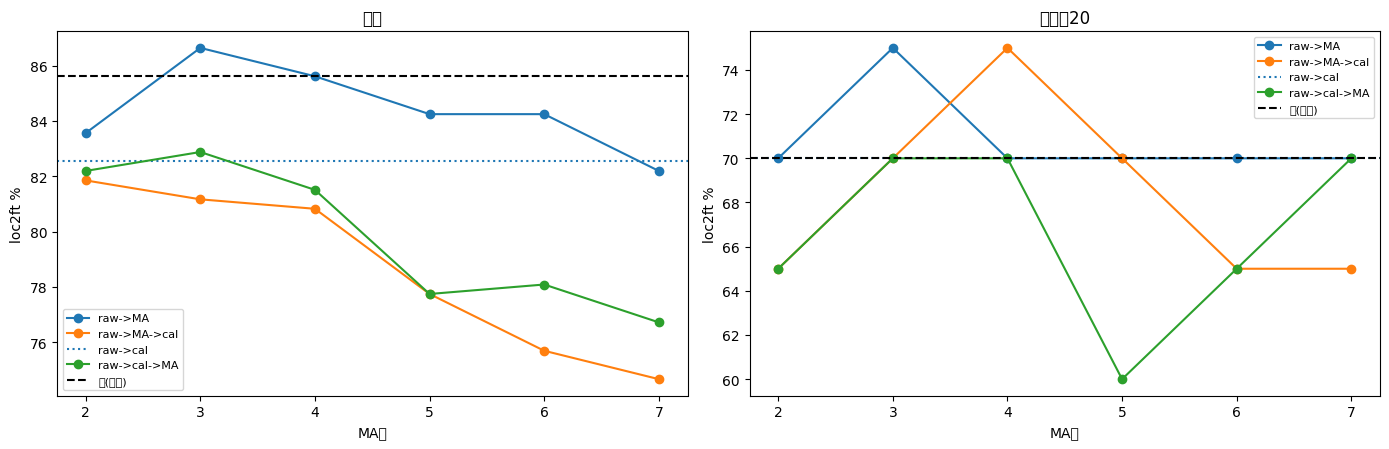


★読み: 各パイプが生(黒破線)を超えるか。超えるMA窓があれば前処理の効果。硬い核(右)は20件で評価。


In [26]:
# ===== GR前処理パイプライン比較: raw->MA / raw->MA->較正 / raw->較正 / raw->較正->MA =====
# MA窓 = 2..7。各パイプラインで eval位置特定(シフトスキャン)と一致RMSEを測る。硬い核20件を必ず含める。
# 較正=既知ゾーンで 水平GR≈a*typeGR+b を出し typewellを水平スケールへ(a*tw+b)。較正不変なので MAと可換、
# 違いは「a,bを raw で出すか / MA後で出すか」と「水平evalをMAするか」。
import glob, os
OFFp=np.arange(-30,30.01,1.0); MAW=[2,3,4,5,6,7]
def ma(x,w):
    if w<=1: return x
    return np.convolve(np.nan_to_num(x,nan=np.nanmean(x)),np.ones(w)/w,mode="same")
def locrmse(egr, twt, tgrid, etrue):
    ms=np.array([rmse(egr, np.interp(etrue+dz,twt,tgrid)) for dz in OFFp])
    return abs(OFFp[int(np.argmin(ms))]), rmse(egr, np.interp(etrue,twt,tgrid))

allw=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))
EVALW=list(dict.fromkeys(allw[:280]+HARD))     # 易280 + 硬い核20(必ず含める)
PIPES=["raw->MA","raw->MA->cal","raw->cal","raw->cal->MA"]
# 結果: pipe -> window -> list[(loc,rmse,is_hard)]。raw->cal は窓非依存なので w=0 に格納。
D={p:{w:[] for w in (MAW if p!="raw->cal" else [0])} for p in PIPES}
RAW0=[]   # 生(MA無較正無)基準
for wid in EVALW:
    hw=pd.read_csv(TR/f"{wid}__horizontal_well.csv"); tw=pd.read_csv(TR/f"{wid}__typewell.csv").sort_values("TVT")
    if "TVT" not in hw or hw.TVT.isna().all(): continue
    kn=hw[hw.TVT_input.notna()]; ev=hw[hw.TVT_input.isna()]
    if len(kn)<30 or len(ev)<20: continue
    h=hw.GR.astype(float).interpolate(limit_direction="both").to_numpy(float)
    kp=hw.index.get_indexer(kn.index); ep=hw.index.get_indexer(ev.index)
    twt=tw.TVT.to_numpy(float); twg=tw.GR.to_numpy(float)
    ktrue=kn.TVT_input.to_numpy(float); etrue=ev.TVT.to_numpy(float); H=wid in HARD
    aR,bR=affine(np.interp(ktrue,twt,twg), h[kp])          # 較正(raw基準)
    RAW0.append((locrmse(h[ep],twt,twg,etrue)[0], H))
    # raw->cal(窓非依存)
    l,r=locrmse(h[ep], twt, aR*twg+bR, etrue); D["raw->cal"][0].append((l,r,H))
    for w in MAW:
        hma=ma(h,w); twma=ma(twg,w)
        # raw->MA
        l,r=locrmse(hma[ep], twt, twma, etrue); D["raw->MA"][w].append((l,r,H))
        # raw->MA->cal(a,bをMA後で出す)
        a2,b2=affine(np.interp(ktrue,twt,twma), hma[kp])
        l,r=locrmse(hma[ep], twt, a2*twma+b2, etrue); D["raw->MA->cal"][w].append((l,r,H))
        # raw->cal->MA(a,bはraw, その後 typewell(較正済)をMA)
        l,r=locrmse(hma[ep], twt, ma(aR*twg+bR,w), etrue); D["raw->cal->MA"][w].append((l,r,H))

def pct2(arr, hard=None):
    loc=np.array([x[0] for x in arr]); hd=np.array([x[2] for x in arr])
    if hard is True: loc=loc[hd]
    if hard is False: loc=loc[~hd]
    return (loc<=2).mean()*100 if len(loc) else np.nan
def medrmse(arr):
    return float(np.median([x[1] for x in arr]))

rl=np.array([x[0] for x in RAW0]); rh=np.array([x[1] for x in RAW0])
print(f"基準 生(MA無較正無): 全loc2ft={ (rl<=2).mean()*100:.0f}%  硬={ (rl[rh]<=2).mean()*100:.0f}%\n")
print(f"{'pipeline':>14s} {'MA':>3s} {'全loc2ft%':>9s} {'rmse中央':>8s} {'硬loc2ft%':>9s}")
for p in PIPES:
    for w in (MAW if p!="raw->cal" else [0]):
        arr=D[p][w]; tag="-" if w==0 else str(w)
        print(f"{p:>14s} {tag:>3s} {pct2(arr):8.0f}% {medrmse(arr):8.2f} {pct2(arr,True):8.0f}%")

fig,ax=plt.subplots(1,2,figsize=(14,4.6))
for p in PIPES:
    if p=="raw->cal":
        ax[0].axhline(pct2(D[p][0]),ls=":",label=p); ax[1].axhline(pct2(D[p][0],True),ls=":",label=p); continue
    ax[0].plot(MAW,[pct2(D[p][w]) for w in MAW],"o-",label=p)
    ax[1].plot(MAW,[pct2(D[p][w],True) for w in MAW],"o-",label=p)
for a,t,base in ((ax[0],"全体",(rl<=2).mean()*100),(ax[1],"硬い核20",(rl[rh]<=2).mean()*100)):
    a.axhline(base,color="k",ls="--",label="生(基準)"); a.set_xlabel("MA窓"); a.set_ylabel("loc2ft %"); a.set_title(t); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("\n★読み: 各パイプが生(黒破線)を超えるか。超えるMA窓があれば前処理の効果。硬い核(右)は20件で評価。")

集計坑井 292 (硬い核 20)

      repr  全loc2ft%  硬loc2ft%     eval一致中央
       raw       86%       70%        10.79
       ma3       86%       70%        10.25
       ma5       84%       70%        10.69
     agc21        9%       10%        39.31
      rank       61%       65%        24.45
     deriv        2%        0%        35.45
  quantile       63%       65%        22.39
       cal       83%       70%        10.67


C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1828703321.py:64: UserWarning: Glyph 20301 (\N{CJK UNIFIED IDEOGRAPH-4F4D}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1828703321.py:64: UserWarning: Glyph 32622 (\N{CJK UNIFIED IDEOGRAPH-7F6E}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1828703321.py:64: UserWarning: Glyph 29305 (\N{CJK UNIFIED IDEOGRAPH-7279}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1828703321.py:64: UserWarning: Glyph 23450 (\N{CJK UNIFIED IDEOGRAPH-5B9A}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka256\AppData\Local\Temp\ipykernel_25856\1828703321.py:64: UserWarning: Glyph 34920 (\N{CJK UNIFIED IDEOGRAPH-8868}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
C:\Users\kosaka

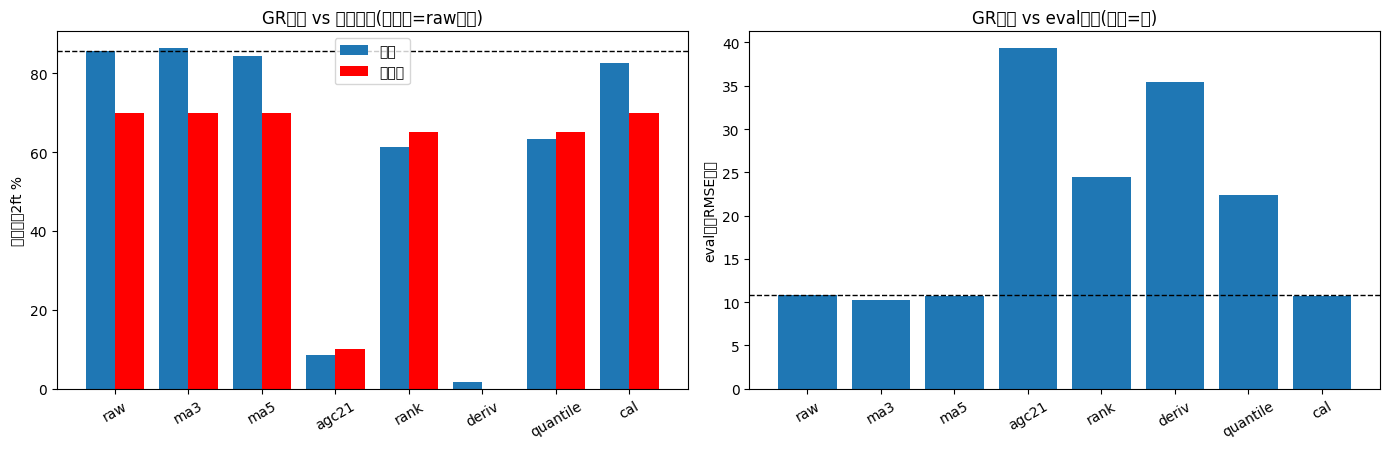


★読み: rawを超える表現があるか(全体/硬い核)。硬い核で効く表現は相補=v20特徴軸の候補。


In [27]:
# ===== GR別表現の比較: ma / agc / rank / 微分 / 分位点 / 較正(localization + eval一致) =====
# 両側に同変換 → typewell生GRスケールへ正規化 → シフトスキャンで位置特定。硬い核20件を必ず含める。
import glob, os
OFFr=np.arange(-30,30.01,1.0)
def _ma(s,w): return pd.Series(s).rolling(int(w),center=True,min_periods=1).mean().to_numpy()
def _agc(s,w):
    a=pd.Series(s).rolling(int(w),center=True,min_periods=1)
    mn=a.mean().to_numpy(); sd=a.std().to_numpy(); sd=np.where(~np.isfinite(sd)|(sd<1e-6),1.,sd)
    return (np.asarray(s,float)-mn)/sd
def _rank(s): return np.argsort(np.argsort(np.asarray(s,float)))/max(len(s)-1,1)
def _qmap(h,tw,nq=201):
    qs=np.linspace(0,1,nq); return np.interp(h,np.nanquantile(h,qs),np.nanquantile(tw,qs))
def _norm(refraw,Th,Ttw):
    mt=np.nanmean(Ttw); st=np.nanstd(Ttw)+1e-6; gm=np.nanmean(refraw); gsd=np.nanstd(refraw)+1e-6
    f=lambda z: gm+gsd*((np.asarray(z,float)-mt)/st); return f(Th),f(Ttw)

REPRS=["raw","ma3","ma5","agc21","rank","deriv","quantile","cal"]
def build(label,h,md,twg,twt,ktrue,hknown):
    if label=="raw": return h,twg
    if label.startswith("ma"): w=int(label[2:]); return _norm(twg,_ma(h,w),_ma(twg,w))
    if label.startswith("agc"): w=int(label[3:]); return _norm(twg,_agc(h,w),_agc(twg,w))
    if label=="rank": return _norm(twg,_rank(h),_rank(twg))
    if label=="deriv": return _norm(twg,np.gradient(h,md),np.gradient(twg,twt))
    if label=="quantile": return _qmap(h,twg),twg
    if label=="cal":
        a,b=affine(np.interp(ktrue,twt,twg),hknown); return h,a*twg+b
def locrmse(hp,twp,twt,etrue,ep):
    egr=hp[ep]; ms=np.array([rmse(egr,np.interp(etrue+dz,twt,twp)) for dz in OFFr])
    return abs(OFFr[int(np.argmin(ms))]), rmse(egr,np.interp(etrue,twt,twp))

allw=sorted(os.path.basename(q).split("__")[0] for q in glob.glob(str(TR/"*__horizontal_well.csv")))
EVALW=list(dict.fromkeys(allw[:280]+HARD))
R={lab:[] for lab in REPRS}
for wid in EVALW:
    hw=pd.read_csv(TR/f"{wid}__horizontal_well.csv"); tw=pd.read_csv(TR/f"{wid}__typewell.csv").sort_values("TVT")
    if "TVT" not in hw or hw.TVT.isna().all(): continue
    kn=hw[hw.TVT_input.notna()]; ev=hw[hw.TVT_input.isna()]
    if len(kn)<30 or len(ev)<20: continue
    h=hw.GR.astype(float).interpolate(limit_direction="both").to_numpy(float); md=hw.MD.astype(float).to_numpy(float)
    kp=hw.index.get_indexer(kn.index); ep=hw.index.get_indexer(ev.index)
    twt=tw.TVT.to_numpy(float); twg=tw.GR.to_numpy(float)
    ktrue=kn.TVT_input.to_numpy(float); etrue=ev.TVT.to_numpy(float); H=wid in HARD
    for lab in REPRS:
        hp,twp=build(lab,h,md,twg,twt,ktrue,h[kp])
        loc,rm=locrmse(hp,twp,twt,etrue,ep); R[lab].append((loc,rm,H))

def stat(arr,hard=None):
    loc=np.array([x[0] for x in arr]); hd=np.array([x[2] for x in arr])
    if hard: loc=loc[hd]
    return (loc<=2).mean()*100 if len(loc) else np.nan
def medr(arr): return float(np.median([x[1] for x in arr]))
print(f"集計坑井 {len(R['raw'])} (硬い核 {int(np.sum([x[2] for x in R['raw']]))})\n")
print(f"{'repr':>10s} {'全loc2ft%':>9s} {'硬loc2ft%':>9s} {'eval一致中央':>12s}")
for lab in REPRS:
    print(f"{lab:>10s} {stat(R[lab]):8.0f}% {stat(R[lab],True):8.0f}% {medr(R[lab]):12.2f}")

fig,ax=plt.subplots(1,2,figsize=(14,4.6)); xs=range(len(REPRS))
ax[0].bar([x-0.2 for x in xs],[stat(R[l]) for l in REPRS],0.4,label="全体")
ax[0].bar([x+0.2 for x in xs],[stat(R[l],True) for l in REPRS],0.4,color="red",label="硬い核")
ax[0].axhline(stat(R["raw"]),color="k",ls="--",lw=1); ax[0].set_xticks(list(xs)); ax[0].set_xticklabels(REPRS,rotation=30)
ax[0].set_ylabel("位置特定2ft %"); ax[0].set_title("GR表現 vs 位置特定(黒破線=raw全体)"); ax[0].legend()
ax[1].bar(list(xs),[medr(R[l]) for l in REPRS],color="tab:blue"); ax[1].axhline(medr(R["raw"]),color="k",ls="--",lw=1)
ax[1].set_xticks(list(xs)); ax[1].set_xticklabels(REPRS,rotation=30); ax[1].set_ylabel("eval一致RMSE中央"); ax[1].set_title("GR表現 vs eval一致(低い=良)")
plt.tight_layout(); plt.show()
print("\n★読み: rawを超える表現があるか(全体/硬い核)。硬い核で効く表現は相補=v20特徴軸の候補。")